![Générer des visages avec un auto-encodeur](https://raw.githubusercontent.com/yayefatou-lam/autoencodeur-visages/main/assets/banner.png)

`PyTorch` &nbsp; `auto-encodeur convolutif` &nbsp; `CelebA 64×64` &nbsp; `projet en cours`

**Yaye Fatou Lam**, **Imad Asennane**, **Serigne Touba Mbaye** et **Ndèye Marème Gueye** · Master 2 IOSD (Image, Optimisation et Sciences des Données), Université de Bordeaux · 2026

| $\color{#C2643F}{\mathbf{0{,}0073}}$ | $\color{#C2643F}{\mathbf{36\,000}}$ | $\color{#C2643F}{\mathbf{1{,}9\,\text{M}}}$ | $\color{#C2643F}{\mathbf{k = 64}}$ |
|:---:|:---:|:---:|:---:|
| erreur de reconstruction (MSE) sur le test | visages CelebA | paramètres | valeurs dans le code latent |

> $\color{#6F8A5B}{\mathtt{>}}$ **Sommaire**
>
> 1. L'idée
> 2. Les modèles testés
> 3. Configuration
> 4. Les données
> 5. Le modèle
> 6. Entraînement
> 7. Reconstructions
> 8. Génération de visages
> 9. Bilan et suite

## $\color{#C2643F}{\mathtt{01}}$ &nbsp; L'idée

Un auto-encodeur est un réseau de neurones entraîné à recopier son entrée sur sa sortie, en passant par un goulot d'étranglement. Il a deux parties :

- l'**encodeur** $E_\varphi$ compresse une image $x$ (ici $3 \times 64 \times 64 = 12\,288$ valeurs) en un code $z = E_\varphi(x)$ de seulement $k = 64$ valeurs ;
- le **décodeur** $D_\theta$ reconstruit une image $\hat x = D_\theta(z)$ à partir de ce code.

Comme le code est 192 fois plus petit que l'image, le réseau ne peut pas copier les pixels : il doit apprendre ce qui compte dans un visage. On cherche les paramètres qui minimisent l'erreur de reconstruction moyenne sur les $N$ images d'entraînement :

$$
\min_{\varphi,\theta} \; \frac{1}{N} \sum_{n=1}^{N} \big\| D_\theta(E_\varphi(x_n)) - x_n \big\|^2 .
$$


> $\color{#C2643F}{\mathtt{>}}$ **Et pour générer ?**
>
> Une fois l'entraînement terminé, on garde seulement le décodeur : on tire un code $z$ au hasard et on calcule $D_\theta(z)$. Toute la difficulté est de savoir comment tirer $z$, c'est l'objet de la section 08.

## $\color{#C2643F}{\mathtt{02}}$ &nbsp; Les modèles testés

Ce notebook présente le modèle retenu. Avant d'y arriver, on a comparé plusieurs architectures et plusieurs tailles de code.

**Premiers essais sur Fashion-MNIST** (images de vêtements 28 × 28 en niveaux de gris, code de taille 16, 50 époques)

| Modèle | Paramètres | MSE sur le test |
| --- | ---: | ---: |
| Dense, 1 couche cachée de chaque côté | 321 200 | 0,0111 |
| Dense, 2 couches cachées de chaque côté | 437 664 | 0,0110 |
| $\color{#C2643F}{\bullet}$ **Convolutif** | 170 193 | **0,0093** |

Le réseau convolutif reconstruit le mieux, avec environ deux fois moins de paramètres : il tient compte du fait que deux pixels voisins sont liés, ce qu'un réseau dense ignore. C'est l'architecture qu'on a gardée pour les visages.

**Visages CelebA : influence de la taille du code $k$** (même réseau convolutif, meilleure époque sur la validation)

| $k$ | Compression | Paramètres | MSE de validation | Précision des tirages $\mathcal{N}(\hat\mu, \hat\Sigma)$ |
| ---: | ---: | ---: | ---: | ---: |
| 32 | 384 | 1 647 715 | 0,0102 | 34,5 % |
| $\color{#C2643F}{\bullet}$ **64** | **192** | **1 909 891** | **0,0071** | **18,5 %** |
| 128 | 96 | 2 434 243 | 0,0049 | 10,4 % |
| 256 | 48 | 3 482 947 | 0,0034 | 7,3 % |

Plus le code est grand, meilleure est la reconstruction, mais moins les tirages ressemblent à de vrais codes : la précision (définie en section 08) chute de 34,5 % à 7,3 %. Avec $k = 32$, les reconstructions sont trop floues ; au-delà de 64, la génération se dégrade. On présente ici $k = 64$, notre compromis entre les deux.


> $\color{#6F8A5B}{\mathtt{>}}$ **Méthode**
>
> Les images de test ne servent à aucun choix : elles sont utilisées une seule fois, pour l'évaluation finale.

## $\color{#C2643F}{\mathtt{03}}$ &nbsp; Configuration

Le notebook est prévu pour Google Colab avec un GPU (Exécution > Modifier le type d'exécution > GPU). Toutes les graines aléatoires sont fixées pour que les résultats soient reproductibles.

In [1]:
%pip install -q datasets

import copy
import os
import shutil
import warnings

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"     # notebook publié : pas de barres de téléchargement
os.environ["HF_HUB_VERBOSITY"] = "error"             # ni d'avertissements de Hugging Face
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import torch
import torch.nn as nn
from datasets import disable_progress_bars, load_dataset
from matplotlib.patches import FancyBboxPatch
from torch.utils.data import DataLoader, TensorDataset

disable_progress_bars()

In [2]:
# Reproductibilité
SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Données
DATA_DIR = "data"
IMG_SIZE = 64
N_TRAIN, N_VAL, N_TEST = 30_000, 3_000, 3_000

# Modèle et entraînement
K = 64              # taille du code latent z
EPOCHS = 50
BATCH_SIZE = 128
LR = 1e-3

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device :", device)

device : cuda


In [3]:
# Thème des figures : fond sombre, accents terracotta lumineux
COLORS = {
    "fond": "#16110F",
    "panneau": "#1F1915",
    "grille": "#3A2E28",
    "texte": "#F2E6DA",
    "gris": "#A08C7E",
    "terracotta": "#E0784F",
    "cuivre": "#F2A57E",
    "sauge": "#9FB28C",
    "ocre": "#E6B65C",
}

plt.rcParams.update({
    "figure.facecolor": COLORS["fond"],
    "savefig.facecolor": COLORS["fond"],
    "axes.facecolor": COLORS["panneau"],
    "axes.edgecolor": COLORS["grille"],
    "axes.labelcolor": COLORS["texte"],
    "axes.titlecolor": COLORS["texte"],
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": COLORS["grille"],
    "grid.linestyle": ":",
    "xtick.color": COLORS["gris"],
    "ytick.color": COLORS["gris"],
    "text.color": COLORS["texte"],
    "legend.frameon": False,
    "font.family": "monospace",
    "font.size": 10,
})

os.makedirs("assets", exist_ok=True)


def glow_plot(ax, x, y, color, label=None, ls="-"):
    """Courbe avec un halo lumineux : la même courbe tracée plusieurs fois, de plus en plus large et transparente."""
    for lw, alpha in [(10, 0.05), (6, 0.10), (3.5, 0.20)]:
        ax.plot(x, y, color=color, lw=lw, alpha=alpha, ls=ls, solid_capstyle="round")
    ax.plot(x, y, color=color, lw=1.8, ls=ls, label=label)


def finish(fig, title=None, name=None):
    """Titre de la figure, mise en page, enregistrement éventuel dans assets/, affichage."""
    if title:
        fig.suptitle(title.upper(), x=0.01, ha="left", fontweight="bold", fontsize=12, color=COLORS["cuivre"])
    fig.tight_layout()
    if name:
        fig.savefig(f"assets/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## $\color{#C2643F}{\mathtt{04}}$ &nbsp; Les données

[CelebA](https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html) contient plus de 200 000 photos de visages de célébrités, déjà centrées sur le visage. On tire au hasard, avec une graine fixe, un sous-ensemble dans chacun des trois splits officiels :

| Ensemble | Images | Rôle |
| --- | ---: | --- |
| Train | 30 000 | entraîner le réseau, puis estimer la loi des codes pour la génération |
| Validation | 3 000 | suivre l'erreur pendant l'entraînement et garder la meilleure époque |
| Test | 3 000 | évaluation finale uniquement |

Prétraitement de chaque image : recadrage centré en 148 × 148 pour garder le visage et enlever une partie du fond, réduction en 64 × 64, puis pixels ramenés dans $[0, 1]$. Les images restent au format $(3, 64, 64)$ : le réseau convolutif travaille directement sur l'image, sans l'aplatir.

In [4]:
def load_split(split, n):
    """Sous-ensemble aléatoire (mais reproductible) de n images d'un split officiel de CelebA."""
    ds = load_dataset("tpremoli/CelebA-attrs", split=split, cache_dir=DATA_DIR)
    return ds.shuffle(seed=SEED).select(range(n))


def to_array(img):
    """Recadrage centré 148 x 148, puis réduction en 64 x 64. Renvoie un tableau (64, 64, 3)."""
    img = img.convert("RGB")
    w, h = img.size
    c = min(148, w, h)
    left, top = (w - c) // 2, (h - c) // 2
    img = img.crop((left, top, left + c, top + c)).resize((IMG_SIZE, IMG_SIZE))
    return np.asarray(img)


def to_tensor(ds):
    """Toutes les images du dataset -> tenseur (N, 3, 64, 64) de pixels dans [0, 1]."""
    X = np.stack([to_array(ex["image"]) for ex in ds])     # (N, 64, 64, 3), entiers de 0 à 255
    X = np.ascontiguousarray(X.transpose(0, 3, 1, 2))        # (N, 3, 64, 64)
    return torch.from_numpy(X).float().div_(255.0)


hf_train = load_split("train", N_TRAIN)
hf_val = load_split("validation", N_VAL)
hf_test = load_split("test", N_TEST)

X_train = to_tensor(hf_train)
X_val = to_tensor(hf_val)
X_test = to_tensor(hf_test)
is_male = np.asarray(list(hf_train["Male"])) > 0       # attribut de CelebA, sert seulement à colorer une figure

g = torch.Generator().manual_seed(SEED)                 # ordre des mini-batchs reproductible
train_loader = DataLoader(TensorDataset(X_train), batch_size=BATCH_SIZE, shuffle=True, generator=g)
val_loader = DataLoader(TensorDataset(X_val), batch_size=256)
test_loader = DataLoader(TensorDataset(X_test), batch_size=256)

print("train :", tuple(X_train.shape), "  validation :", tuple(X_val.shape), "  test :", tuple(X_test.shape))

train : (30000, 3, 64, 64)   validation : (3000, 3, 64, 64)   test : (3000, 3, 64, 64)


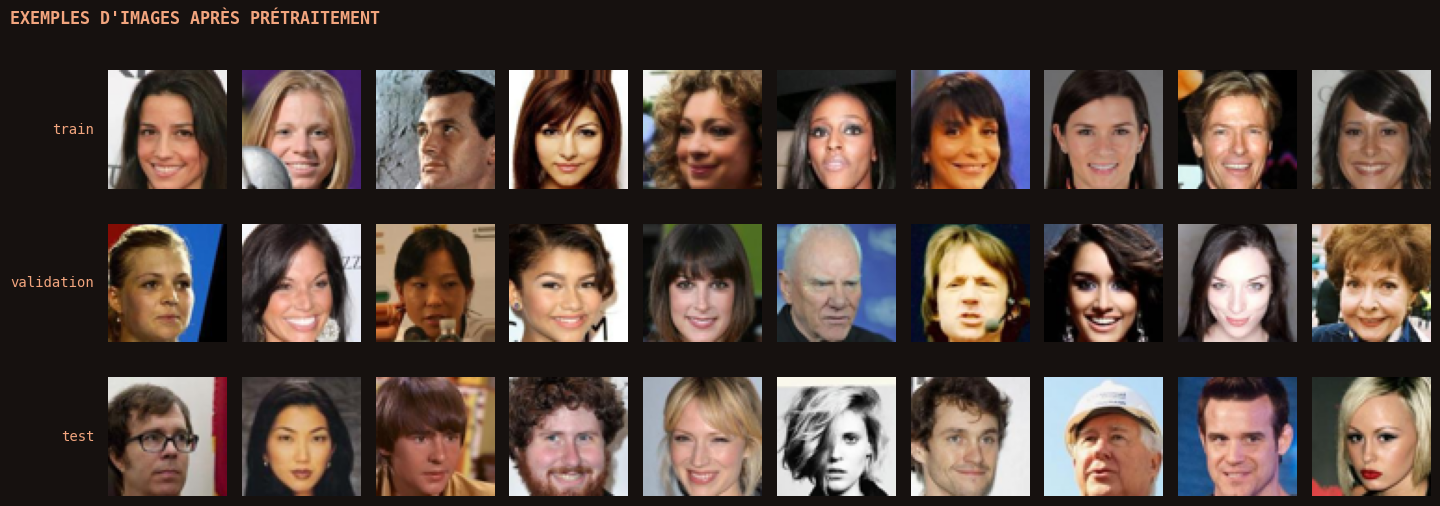

In [5]:
def show_faces(rows, n=10, title=None, name=None):
    """Grille de visages : une ligne de n images par couple (étiquette, tenseur (N, 3, 64, 64))."""
    fig, axes = plt.subplots(len(rows), n, figsize=(1.45 * n, 1.55 * len(rows) + 0.7), squeeze=False)
    for r, (label, X) in enumerate(rows):
        for i in range(n):
            ax = axes[r, i]
            ax.imshow(X[i].permute(1, 2, 0).cpu().numpy())     # (3, 64, 64) -> (64, 64, 3)
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
            for spine in ax.spines.values():
                spine.set_visible(False)
        axes[r, 0].set_ylabel(label, rotation=0, ha="right", va="center", labelpad=10, color=COLORS["cuivre"])
    finish(fig, title, name)


show_faces([("train", X_train), ("validation", X_val), ("test", X_test)],
           title="Exemples d'images après prétraitement", name="apercu_donnees")

## $\color{#C2643F}{\mathtt{05}}$ &nbsp; Le modèle

Chaque convolution de pas 2 divise la taille de l'image par 2, chaque convolution transposée la multiplie par 2. L'encodeur passe ainsi de $64 \times 64$ à $4 \times 4$, puis une couche linéaire donne le code $z \in \mathbb{R}^{64}$. Le décodeur fait le chemin inverse.

| Partie | Couches | Taille en sortie |
| --- | --- | --- |
| Entrée | | $3 \times 64 \times 64$ |
| Encodeur $E_\varphi$ | 4 blocs Conv2d (pas 2) + BatchNorm + ReLU | $256 \times 4 \times 4$ |
| | Flatten, Linear | $z \in \mathbb{R}^{64}$ |
| Décodeur $D_\theta$ | Linear + ReLU, Unflatten | $256 \times 4 \times 4$ |
| | 3 blocs ConvTranspose2d (pas 2) + BatchNorm + ReLU | $32 \times 32 \times 32$ |
| | ConvTranspose2d + Sigmoïde | $3 \times 64 \times 64$ |


> $\color{#C2643F}{\mathtt{>}}$ **Trois choix à noter**
>
> - pas d'activation sur le code : $z$ peut prendre n'importe quelle valeur réelle ;
> - la sigmoïde en sortie donne des pixels entre 0 et 1, comme les images d'entrée ;
> - la BatchNorm stabilise l'entraînement. Elle se comporte différemment en mode `train()` et en mode `eval()`, d'où les appels à `model.eval()` avant d'encoder, de décoder ou de générer.

In [6]:
def down(c_in, c_out):
    """Convolution de pas 2 : divise la taille de l'image par 2."""
    return nn.Sequential(nn.Conv2d(c_in, c_out, 4, stride=2, padding=1), nn.BatchNorm2d(c_out), nn.ReLU())


def up(c_in, c_out):
    """Convolution transposée de pas 2 : multiplie la taille de l'image par 2."""
    return nn.Sequential(nn.ConvTranspose2d(c_in, c_out, 4, stride=2, padding=1), nn.BatchNorm2d(c_out), nn.ReLU())


class Encoder(nn.Module):
    """E_phi : image 3 x 64 x 64 -> code z dans R^k."""

    def __init__(self, k):
        super().__init__()
        self.net = nn.Sequential(
            down(3, 32),                    # 32 x 32 x 32
            down(32, 64),                   # 64 x 16 x 16
            down(64, 128),                  # 128 x 8 x 8
            down(128, 256),                 # 256 x 4 x 4
            nn.Flatten(),                   # vecteur de taille 4096
            nn.Linear(256 * 4 * 4, k),      # pas d'activation : z est libre dans R^k
        )

    def forward(self, x):
        return self.net(x)


class Decoder(nn.Module):
    """D_theta : code z dans R^k -> image 3 x 64 x 64."""

    def __init__(self, k):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(k, 256 * 4 * 4), nn.ReLU(),
            nn.Unflatten(1, (256, 4, 4)),
            up(256, 128),                   # 128 x 8 x 8
            up(128, 64),                    # 64 x 16 x 16
            up(64, 32),                     # 32 x 32 x 32
            nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1), nn.Sigmoid(),     # 3 x 64 x 64, pixels dans (0, 1)
        )

    def forward(self, z):
        return self.net(z)


class AutoEncoder(nn.Module):
    """x -> z = E(x) -> x_hat = D(z)."""

    def __init__(self, k):
        super().__init__()
        self.E = Encoder(k)
        self.D = Decoder(k)

    def forward(self, x):
        return self.D(self.E(x))


torch.manual_seed(SEED)
model = AutoEncoder(K).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"auto-encodeur k = {K} : {n_params:,} paramètres")

# vérification des dimensions sur un petit batch
x = X_train[:8].to(device)
print("x :", tuple(x.shape), "  z :", tuple(model.E(x).shape), "  x_hat :", tuple(model(x).shape))

auto-encodeur k = 64 : 1,909,891 paramètres
x : (8, 3, 64, 64)   z : (8, 64)   x_hat : (8, 3, 64, 64)


## $\color{#C2643F}{\mathtt{06}}$ &nbsp; Entraînement

On minimise l'erreur quadratique moyenne par pixel (MSE) entre l'image et sa reconstruction, avec l'optimiseur Adam (pas de $10^{-3}$) sur des mini-batchs de 128 images. À chaque époque, on mesure aussi l'erreur sur la validation, et on garde à la fin les poids de la **meilleure époque**, pas ceux de la dernière.

In [7]:
loss_fn = nn.MSELoss()


@torch.no_grad()
def evaluate(model, loader):
    """MSE moyenne par pixel sur toutes les images du loader."""
    model.eval()
    total = 0.0
    for (x,) in loader:
        x = x.to(device)
        total += loss_fn(model(x), x).item() * len(x)
    return total / len(loader.dataset)


def fit(model, epochs, lr=LR):
    """Entraîne sur le train, suit la MSE sur la validation et recharge les poids de la meilleure époque."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train": [], "val": []}
    best_val, best_state = float("inf"), None

    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for (x,) in train_loader:
            x = x.to(device)
            loss = loss_fn(model(x), x)            # || D(E(x)) - x ||^2, moyennée sur les pixels
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(x)
        history["train"].append(total / len(train_loader.dataset))
        history["val"].append(evaluate(model, val_loader))

        if history["val"][-1] < best_val:          # meilleure époque sur la validation
            best_val, best_state = history["val"][-1], copy.deepcopy(model.state_dict())
        if epoch == 1 or epoch % 5 == 0:
            print(f"époque {epoch:3d}   train {history['train'][-1]:.5f}   validation {history['val'][-1]:.5f}")

    model.load_state_dict(best_state)
    return history


history = fit(model, EPOCHS)
torch.save(model.state_dict(), f"autoencoder_celeba_k{K}.pt")     # sauvegarde des poids

époque   1   train 0.02599   validation 0.01464
époque   5   train 0.00878   validation 0.00841
époque  10   train 0.00782   validation 0.00783
époque  15   train 0.00737   validation 0.00777
époque  20   train 0.00712   validation 0.00776
époque  25   train 0.00693   validation 0.00739
époque  30   train 0.00676   validation 0.00718
époque  35   train 0.00663   validation 0.00720
époque  40   train 0.00645   validation 0.00733
époque  45   train 0.00634   validation 0.00713
époque  50   train 0.00628   validation 0.00722


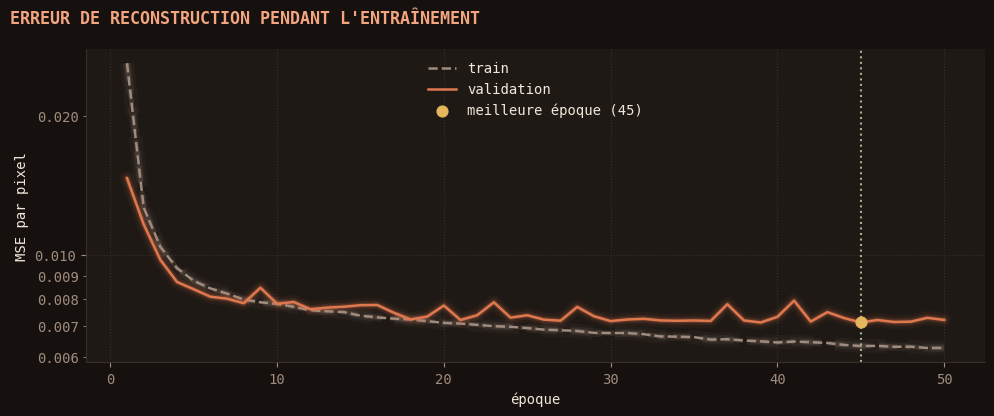

meilleure époque 45 : MSE de validation 0.00713


In [8]:
best_epoch = int(np.argmin(history["val"])) + 1
epochs = range(1, len(history["train"]) + 1)

fig, ax = plt.subplots(figsize=(10, 4.2))
glow_plot(ax, epochs, history["train"], COLORS["gris"], label="train", ls="--")
glow_plot(ax, epochs, history["val"], COLORS["terracotta"], label="validation")
ax.axvline(best_epoch, color=COLORS["sauge"], ls=":", lw=1.5)
ax.scatter([best_epoch], [history["val"][best_epoch - 1]], s=60, color=COLORS["ocre"], zorder=5,
           label=f"meilleure époque ({best_epoch})")
ax.set_yscale("log")
decimals = mticker.FuncFormatter(lambda v, _: f"{v:.3f}")      # 0.010 plutôt que 10^-2
ax.yaxis.set_major_formatter(decimals)
ax.yaxis.set_minor_formatter(decimals)
ax.set_xlabel("époque")
ax.set_ylabel("MSE par pixel")
ax.legend()
finish(fig, "Erreur de reconstruction pendant l'entraînement", name="courbes_loss")

print(f"meilleure époque {best_epoch} : MSE de validation {history['val'][best_epoch - 1]:.5f}")

Les deux courbes descendent ensemble puis restent proches : le modèle n'apprend pas les images d'entraînement par cœur. En fin d'entraînement, l'erreur de validation se stabilise alors que celle du train continue de baisser : c'est pour cela qu'on garde les poids de la meilleure époque plutôt que ceux de la dernière.

## $\color{#C2643F}{\mathtt{07}}$ &nbsp; Reconstructions

On compare des images à leurs reconstructions $\hat x = D_\theta(E_\varphi(x))$, d'abord sur le train, puis sur la validation. L'ordre compte : si les reconstructions sont déjà mauvaises sur le train, le problème vient de l'entraînement ; si elles sont bonnes sur le train mais nettement moins sur la validation, le modèle a sur-appris.

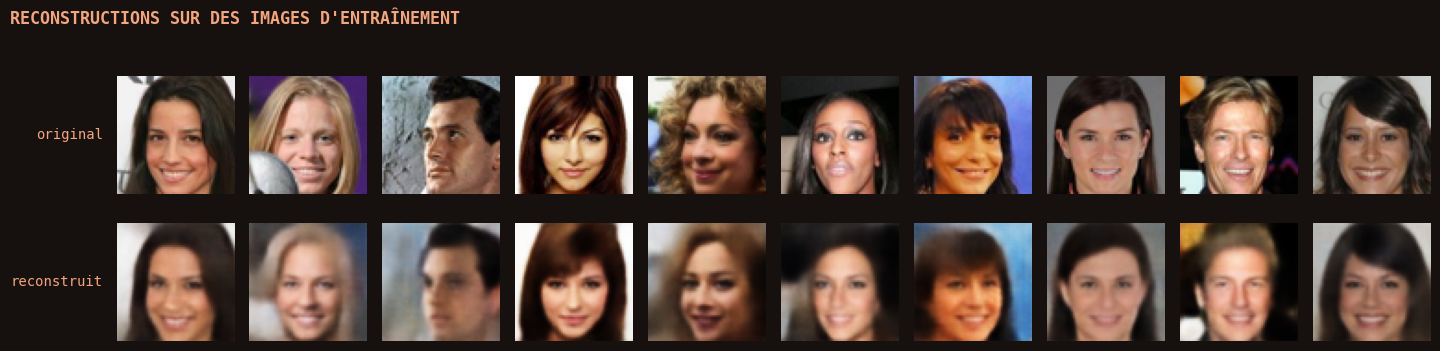

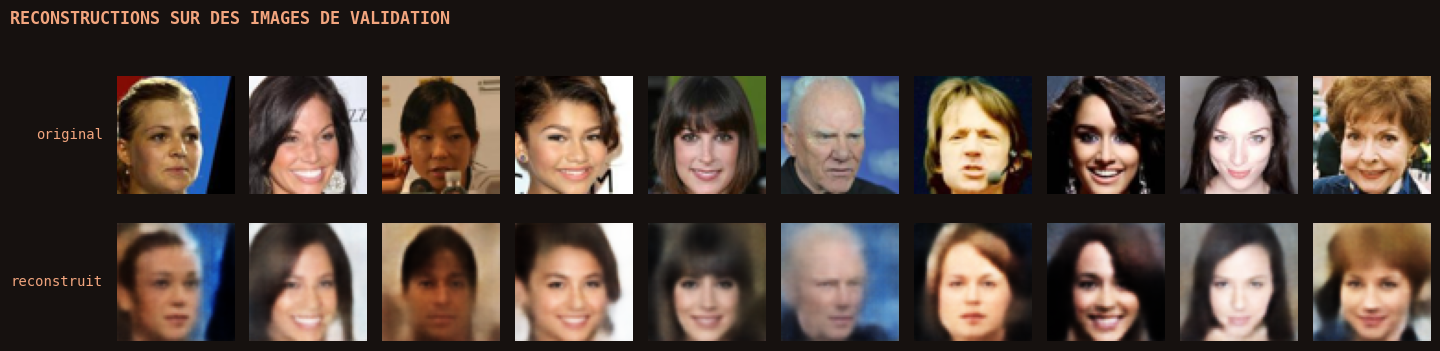

In [9]:
@torch.no_grad()
def reconstruct(model, X, n=10):
    """Reconstructions D(E(x)) des n premières images de X, ramenées sur le CPU."""
    model.eval()
    return model(X[:n].to(device)).cpu()


show_faces([("original", X_train), ("reconstruit", reconstruct(model, X_train))],
           title="Reconstructions sur des images d'entraînement")
show_faces([("original", X_val), ("reconstruit", reconstruct(model, X_val))],
           title="Reconstructions sur des images de validation", name="reconstructions")

Les reconstructions ont la même qualité sur le train et sur la validation : le modèle généralise. Elles sont floues, mais gardent l'essentiel du visage : position, couleur des cheveux et de la peau, expression. Ce flou est attendu avec la MSE : quand le modèle hésite, la prédiction qui minimise l'erreur quadratique est une moyenne des possibilités.

### Meilleures et pires reconstructions

On calcule l'erreur image par image sur toute la validation, pour voir quels visages le modèle reconstruit bien ou mal.

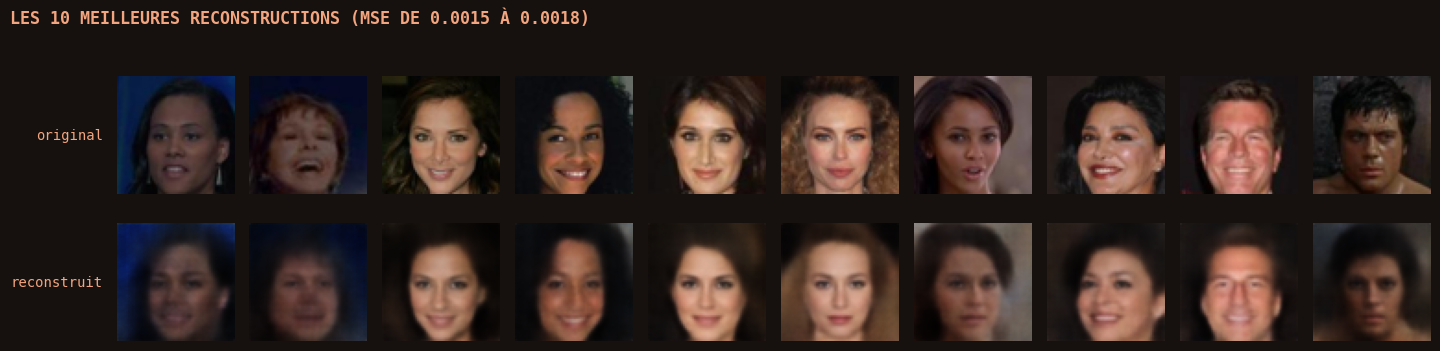

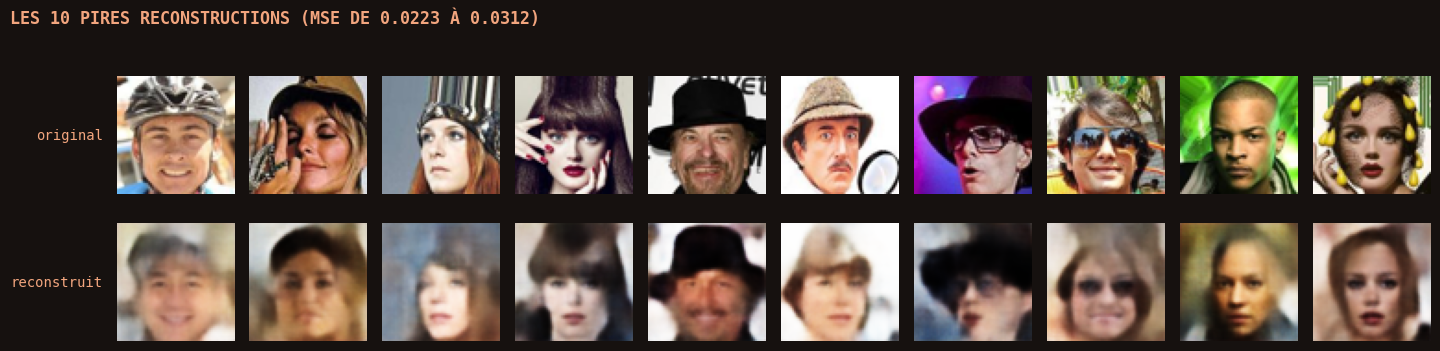

In [10]:
@torch.no_grad()
def mse_per_image(model, X, batch_size=256):
    """MSE par pixel de chaque image de X. Renvoie un tableau (N,)."""
    model.eval()
    errors = []
    for (x,) in DataLoader(TensorDataset(X), batch_size=batch_size):
        x = x.to(device)
        errors.append(((model(x) - x) ** 2).mean(dim=(1, 2, 3)).cpu())
    return torch.cat(errors).numpy()


err_val = mse_per_image(model, X_val)
order = np.argsort(err_val)                 # de la meilleure à la pire reconstruction
best, worst = order[:10], order[-10:]

show_faces([("original", X_val[best]), ("reconstruit", reconstruct(model, X_val[best]))],
           title=f"Les 10 meilleures reconstructions (MSE de {err_val[best[0]]:.4f} à {err_val[best[-1]]:.4f})")
show_faces([("original", X_val[worst]), ("reconstruit", reconstruct(model, X_val[worst]))],
           title=f"Les 10 pires reconstructions (MSE de {err_val[worst[0]]:.4f} à {err_val[worst[-1]]:.4f})")

Les pires reconstructions sont en général des images atypiques (tête tournée, chapeau, lunettes de soleil, fond chargé) : elles sont rares dans les données, donc moins bien apprises.

### Évaluation finale sur le test

In [11]:
mse_val = min(history["val"])
mse_test = evaluate(model, test_loader)
print(f"MSE validation (meilleure époque) : {mse_val:.5f}")
print(f"MSE test                          : {mse_test:.5f}   (écart avec la validation : {(mse_test - mse_val) / mse_val:+.1%})")

MSE validation (meilleure époque) : 0.00713
MSE test                          : 0.00733   (écart avec la validation : +2.8%)


## $\color{#C2643F}{\mathtt{08}}$ &nbsp; Génération de visages

Pour générer, on garde seulement le décodeur : on tire un code $z$ au hasard et on calcule $D_\theta(z)$. On compare deux façons de tirer $z$ :

1. **tirage naïf** $z \sim \mathcal{N}(0, I)$ : la loi gaussienne standard ;
2. **gaussienne ajustée** $z \sim \mathcal{N}(\hat\mu, \hat\Sigma)$ : la gaussienne qui a la même moyenne et la même covariance que les codes $z_n = E_\varphi(x_n)$ des images d'entraînement.

Pour la seconde, on passe par une ACP des codes. Dans la base des axes principaux $V$, les coordonnées sont indépendantes, de variances $\lambda_i$ : on tire $c_i \sim \mathcal{N}(0, \lambda_i)$, puis on revient à la base de départ avec $z = \hat\mu + V c$.

In [12]:
@torch.no_grad()
def encode(model, X, batch_size=512):
    """Codes z = E(x) de toutes les images de X. Renvoie un tableau (N, k)."""
    model.eval()
    Z = [model.E(x.to(device)).cpu() for (x,) in DataLoader(TensorDataset(X), batch_size=batch_size)]
    return torch.cat(Z).numpy().astype("float64")


@torch.no_grad()
def decode(model, Z, batch_size=512):
    """Images D(z) pour chaque ligne de Z (tableau (n, k)). Renvoie un tenseur (n, 3, 64, 64)."""
    model.eval()
    Z = torch.from_numpy(np.asarray(Z, dtype="float32"))
    return torch.cat([model.D(z.to(device)).cpu() for z in Z.split(batch_size)])


def pca(Z):
    """ACP du nuage Z (un code par ligne) par SVD : centre mu, axes principaux V (en colonnes), variances lambda."""
    mu = Z.mean(axis=0)
    _, S, Vt = np.linalg.svd(Z - mu, full_matrices=False)
    return mu, Vt.T, S ** 2 / (len(Z) - 1)


def sample_gaussian(mu, V, lam, n):
    """n tirages de N(mu, Sigma) avec Sigma = V diag(lam) V^T : c_i ~ N(0, lam_i), puis z = mu + V c."""
    c = np.random.randn(n, len(lam)) * np.sqrt(lam)
    return c @ V.T + mu


Z_train = encode(model, X_train)
mu, V, lam = pca(Z_train)
print(f"centre des codes : norme {np.linalg.norm(mu):.1f}   (N(0, I) suppose 0)")
print(f"écart-type moyen des coordonnées : {Z_train.std(axis=0).mean():.1f}   (N(0, I) suppose 1)")

centre des codes : norme 27.7   (N(0, I) suppose 0)
écart-type moyen des coordonnées : 8.0   (N(0, I) suppose 1)


Les codes ne sont ni centrés en 0, ni de variance 1 : la loi $\mathcal{N}(0, I)$ n'a ni la bonne position, ni la bonne étendue. On s'attend donc à ce que le tirage naïf donne des codes que le décodeur n'a jamais rencontrés.

### Visages générés

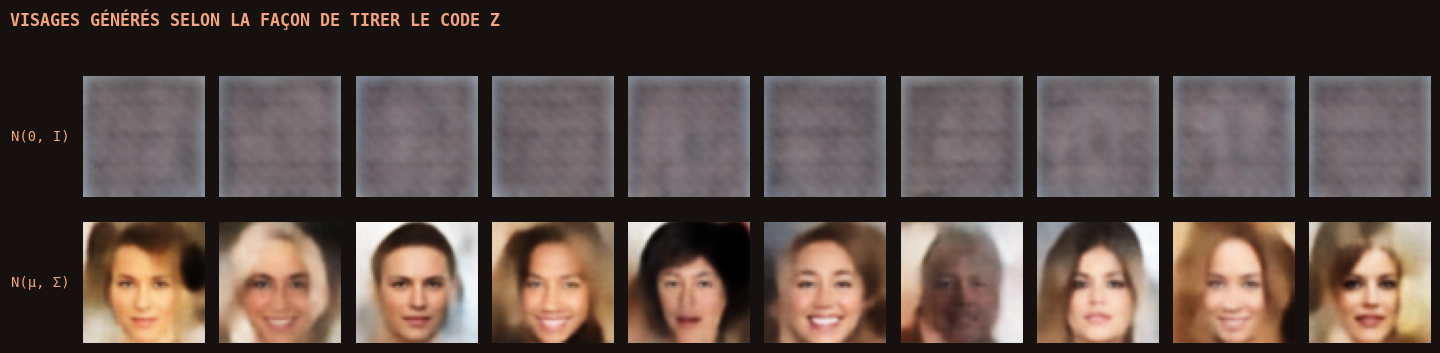

In [13]:
np.random.seed(SEED)
show_faces([("N(0, I)", decode(model, np.random.randn(10, K))),
            ("N(μ, Σ)", decode(model, sample_gaussian(mu, V, lam, 10)))],
           title="Visages générés selon la façon de tirer le code z", name="generation")

Le tirage naïf donne des images peu naturelles, qui se ressemblent toutes. Avec la gaussienne ajustée, on obtient des visages reconnaissables, flous comme les reconstructions, et parfois mal formés.

### Où tombent les tirages ?

On représente les codes d'entraînement dans le plan des deux premiers axes principaux, avec 500 tirages de chaque méthode projetés de la même façon. Les points sont colorés selon l'attribut homme / femme de CelebA, que le modèle n'a jamais vu. Ce plan ne montre que 2 des 64 directions.

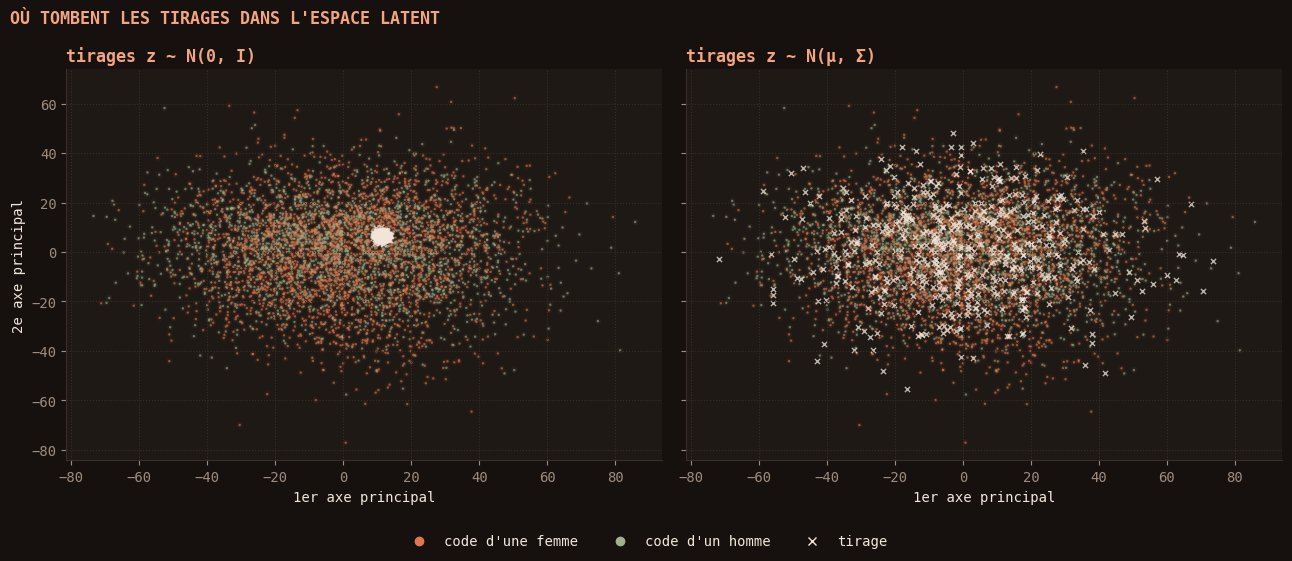

part de variance gardée par les 2 premiers axes : 21.8%


In [19]:
N_PLOT = 5000      # codes affichés, pour garder la figure lisible

np.random.seed(SEED)
C = (Z_train[:N_PLOT] - mu) @ V                                    # coordonnées c = V^T (z - mu)
samples = {"N(0, I)": np.random.randn(500, K),
           "N(μ, Σ)": sample_gaussian(mu, V, lam, 500)}
point_colors = np.where(is_male[:N_PLOT], COLORS["sauge"], COLORS["terracotta"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), sharex=True, sharey=True)
for ax, (label, z) in zip(axes, samples.items()):
    C_s = (z - mu) @ V
    ax.scatter(C[:, 0], C[:, 1], c=point_colors, s=18, alpha=0.06, linewidths=0)     # halo
    ax.scatter(C[:, 0], C[:, 1], c=point_colors, s=3, alpha=0.6, linewidths=0)
    ax.scatter(C_s[:, 0], C_s[:, 1], c=COLORS["texte"], marker="x", s=14, linewidths=1, alpha=0.75)
    ax.set_title(f"tirages z ~ {label}", color=COLORS["cuivre"])
    ax.set_xlabel("1er axe principal")
axes[0].set_ylabel("2e axe principal")

handles = [plt.Line2D([], [], marker="o", ls="", color=COLORS["terracotta"], label="code d'une femme"),
           plt.Line2D([], [], marker="o", ls="", color=COLORS["sauge"], label="code d'un homme"),
           plt.Line2D([], [], marker="x", ls="", color=COLORS["texte"], label="tirage")]
fig.legend(handles=handles, loc="lower center", ncol=3)
fig.suptitle("OÙ TOMBENT LES TIRAGES DANS L'ESPACE LATENT", x=0.01, ha="left", fontweight="bold",
             fontsize=12, color=COLORS["cuivre"])
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig("assets/espace_latent.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"part de variance gardée par les 2 premiers axes : {lam[:2].sum() / lam.sum():.1%}")

Les tirages $\mathcal{N}(0, I)$ restent groupés dans une petite zone, alors que les codes des vrais visages s'étalent beaucoup plus. La gaussienne ajustée recouvre le nuage, mais une seule gaussienne ne suit pas exactement sa forme : une partie des tirages tombe dans des zones où il n'y a pas de vrais codes.

### Mesurer la qualité des tirages : précision et rappel

Regarder des images ne suffit pas : on mesure aussi, dans l'espace latent, si les tirages ressemblent aux codes de vrais visages. On prend comme référence les codes des 3 000 images de test, et pour chaque méthode de tirage 3 000 codes :

- **précision** : part des tirages qui tombent près d'un vrai code. Elle mesure si les tirages sont réalistes ;
- **rappel** : part des vrais codes qui tombent près d'un tirage. Il mesure si les tirages couvrent toute la diversité des visages.

« Près » signifie à une distance inférieure à celle qui sépare un point de son 3e plus proche voisin (méthode de Kynkäänniemi et al., 2019). Ligne de référence : 3 000 codes d'images d'entraînement, c'est-à-dire de vrais visages.

In [20]:
@torch.no_grad()
def kth_nn_radius(A, kk=3):
    """Pour chaque ligne de A, distance à son kk-ième plus proche voisin dans A (le point lui-même exclu)."""
    A = torch.as_tensor(A, dtype=torch.float32, device=device)
    return torch.cdist(A, A).kthvalue(kk + 1, dim=1).values


@torch.no_grad()
def precision_recall(real, generated, kk=3):
    """Précision et rappel (Kynkäänniemi et al., 2019) entre des codes réels et des codes tirés."""
    R = torch.as_tensor(real, dtype=torch.float32, device=device)
    G = torch.as_tensor(generated, dtype=torch.float32, device=device)
    D = torch.cdist(G, R)                                                                   # (n_tirés, n_réels)
    precision = (D <= kth_nn_radius(R, kk)[None, :]).any(dim=1).float().mean().item()      # tirage près d'un vrai code
    recall = (D.T <= kth_nn_radius(G, kk)[None, :]).any(dim=1).float().mean().item()       # vrai code près d'un tirage
    return precision, recall


np.random.seed(SEED)
N_EVAL = len(X_test)
Z_test = encode(model, X_test)
candidates = {"codes du train (référence)": Z_train[np.random.choice(len(Z_train), N_EVAL, replace=False)],
              "N(0, I)": np.random.randn(N_EVAL, K),
              "N(μ, Σ)": sample_gaussian(mu, V, lam, N_EVAL)}

scores = {}
print(f"{'ensemble':28s} {'précision':>10s} {'rappel':>8s}")
for label, z in candidates.items():
    scores[label] = precision_recall(Z_test, z)
    print(f"{label:28s} {scores[label][0]:10.1%} {scores[label][1]:8.1%}")

ensemble                      précision   rappel
codes du train (référence)        60.3%    65.2%
N(0, I)                          100.0%     0.0%
N(μ, Σ)                           19.0%    69.6%


Le tirage naïf a un rappel nul : tous ses tirages tombent dans une petite zone, ce qui rend aussi sa précision trompeuse. La gaussienne ajustée couvre aussi bien la diversité des visages que la référence (rappel du même ordre), mais sa précision reste nettement plus basse : une partie des tirages tombe hors de la région des vrais codes, d'où les visages mal formés.

## $\color{#C2643F}{\mathtt{09}}$ &nbsp; Bilan et suite

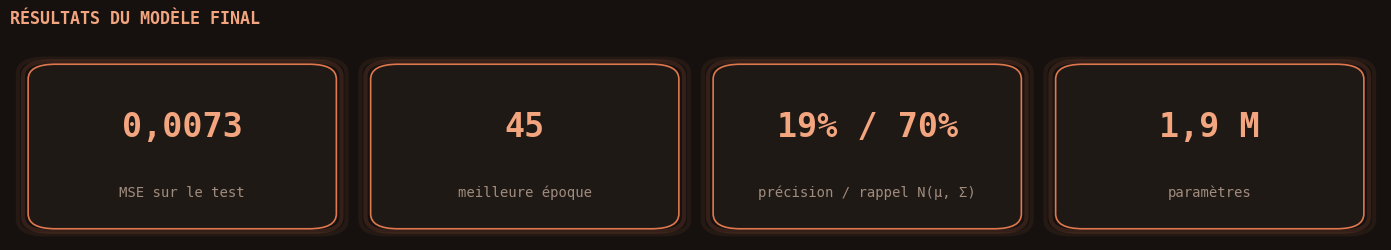

In [21]:
cards = [(f"{mse_test:.4f}", "MSE sur le test"),
         (f"{best_epoch}", "meilleure époque"),
         ("{:.0%} / {:.0%}".format(*scores["N(μ, Σ)"]), "précision / rappel N(μ, Σ)"),
         (f"{n_params / 1e6:.1f} M", "paramètres")]

fig, ax = plt.subplots(figsize=(14, 2.5))
ax.set_xlim(0, len(cards))
ax.set_ylim(0, 1)
ax.axis("off")
for i, (value, label) in enumerate(cards):
    for pad, alpha in [(0.03, 0.08), (0.015, 0.15)]:                  # halo autour de la carte
        ax.add_patch(FancyBboxPatch((i + 0.05 - pad, 0.06 - pad), 0.9 + 2 * pad, 0.88 + 2 * pad,
                                    boxstyle="round,pad=0,rounding_size=0.08", facecolor="none",
                                    edgecolor=COLORS["terracotta"], lw=3, alpha=alpha))
    ax.add_patch(FancyBboxPatch((i + 0.05, 0.06), 0.9, 0.88, boxstyle="round,pad=0,rounding_size=0.08",
                                facecolor=COLORS["panneau"], edgecolor=COLORS["terracotta"], lw=1.2))
    ax.text(i + 0.5, 0.6, value.replace(".", ","), ha="center", va="center",
            fontsize=24, fontweight="bold", color=COLORS["cuivre"])
    ax.text(i + 0.5, 0.25, label, ha="center", va="center", fontsize=10, color=COLORS["gris"])
finish(fig, "Résultats du modèle final", name="resultats")

> $\color{#C2643F}{\mathtt{>}}$ **Ce qu'on retient**
>
> - Un auto-encodeur convolutif de 1,9 million de paramètres reconstruit des visages 64 × 64 à partir d'un code de 64 valeurs, avec une erreur sur le test proche de celle de la validation.
> - Pour générer, le choix de la loi de $z$ est décisif : $\mathcal{N}(0, I)$ échoue parce que les codes ne suivent pas cette loi, alors qu'une gaussienne ajustée sur les codes produit des visages reconnaissables.
> - Une seule gaussienne ne suit pas exactement la forme du nuage des codes : c'est ce que mesure l'écart de précision avec la référence.


> $\color{#6F8A5B}{\mathtt{>}}$ **Suite du projet (en cours)**
>
> 1. Mieux modéliser la loi des codes avec un **mélange de gaussiennes**, dont on choisira le nombre de composantes sur la validation.
> 2. Entraîner un **auto-encodeur variationnel (VAE)**, qui force pendant l'entraînement les codes à suivre $\mathcal{N}(0, I)$.

---

*Annexe : sur Colab, la cellule suivante télécharge le dossier `assets/`, dont les figures sont reprises dans le README du dépôt.*

In [22]:
shutil.make_archive("assets", "zip", "assets")
try:
    from google.colab import files
    files.download("assets.zip")
except ImportError:
    print("figures enregistrées dans le dossier assets/")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>